# ♟️ Chess Numba — 新舊引擎錦標賽對戰 (Colab Tournament Runner)

本 Notebook 用於在 Google Colab 雲端高並行 CPU 環境下，讓 **新版本引擎 (Candidate / New)** 與 **基準版本引擎 (Baseline / Old)** 進行成對換先（Color-swapped Pairs）錦標賽對抗：

### 🎯 本輪對抗設定 (Singular Extensions & Multi-Cut 完整驗證)
* **Engine 1 (New / Candidate)**: `chess_engine/classical`
  * ✅ 修復 `cutoff_cnt[ply + 1]` 跨層洩漏（杜絕兄弟著法遭過度 LMR 減深懲罰）
  * ✅ 阻斷排除搜尋對全局表污染（Correction History 與 Fail-Low 對手獎勵加保護）
  * ✅ 修正 `stop_flag` 檢查順序（杜絕超時中斷 0 分誤觸 Multi-Cut 剪枝）
  * ✅ 對齊 `VALUE_KNOWN_WIN` 門檻（防止殘局已知勝負區間誤剪枝與浪費搜尋）
  * ✅ 修復負延展死碼（`se_tt_score >= beta`）與雙延展 PV 防暴衝保護（`not is_pv`）
* **Engine 2 (Old / Baseline)**: `chess_engine/classical_old`（修正前之舊版生產基準）
* **時控模式**: 固定節點（預設 300,000 nodes 長時控，深度視野約 16~22 層）
* **對戰規格**: 400 局（200 對開局交換白黑），64MB 轉置表，開局庫 `data/openings.epd`
* **統計模型**: SPRT（Sequential Probability Ratio Test）與 Elo 95% 置信區間


In [1]:
# =====================================================================
# 步驟 1: 檢視 Colab 雲端硬體規格與 CPU 核心數
# =====================================================================
!lscpu | grep "Model name\|Socket\|Thread\|NUMA\|CPU(s)"
!free -h
!python3 --version


CPU(s):                                  8
On-line CPU(s) list:                     0-7
Model name:                              AMD EPYC 7B12
Thread(s) per core:                      2
Socket(s):                               1
NUMA node(s):                            1
NUMA node0 CPU(s):                       0-7
               total        used        free      shared  buff/cache   available
Mem:            50Gi       1.3Gi        47Gi       2.2Mi       3.2Gi        49Gi
Swap:             0B          0B          0B
Python 3.13.16


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [2]:
# =====================================================================
# 步驟 2: 載入代碼庫與相依套件
# 支援方式 A：直接從 GitHub 倉庫拉取最新分支
# 支援方式 B：若您上傳了 zip 或放在 Google Drive，亦可解壓至 /content/chess_numba
# =====================================================================
import os

repo_url = "https://github.com/b08203031/chess_numba.git"
branch = "feat-initial-bitboard-setup"

if not os.path.exists('/content/chess_numba'):
    %cd /content
    !git clone -b {branch} {repo_url}

%cd /content/chess_numba
# 若代碼庫已存在，拉取最新變更
!git fetch origin {branch}
!git checkout -f {branch}
!git reset --hard origin/{branch}
!git clean -fd

# 安裝必要相依套件
!pip install -q numba chess numpy matplotlib scipy
print("\n🎉 環境與相依套件安裝完畢！")


/content
Cloning into 'chess_numba'...
remote: Enumerating objects: 3773, done.
remote: Counting objects: 100% (511/511), done.
remote: Compressing objects: 100% (318/318), done.
remote: Total 3773 (delta 387), reused 299 (delta 193), pack-reused 3262 (from 1)
Receiving objects: 100% (3773/3773), 176.90 MiB | 30.37 MiB/s, done.
Resolving deltas: 100% (2610/2610), done.
/content/chess_numba
From https://github.com/b08203031/chess_numba
 * branch            feat-initial-bitboard-setup -> FETCH_HEAD
Already on 'feat-initial-bitboard-setup'
Your branch is up to date with 'origin/feat-initial-bitboard-setup'.
HEAD is now at b0e2cda MIN_SINGULAR_DEPTH = 8 vs 9
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.1/6.1 MB 96.5 MB/s eta 0:00:00ta 0:00:01
  Preparing metadata (setup.py) ... done

🎉 環境與相依套件安裝完畢！


In [3]:
# =====================================================================
# 步驟 3: 嚴格核對新舊引擎代碼差異（驗證 Candidate vs Baseline）
# =====================================================================
import sys
from pathlib import Path

# 1) 清理 Python 模組記憶體快取
for m in list(sys.modules.keys()):
    if 'chess_engine' in m or 'tune_search' in m:
        del sys.modules[m]
!python -m tuner.sync_constants_snapshot
# 2) 顯示新舊版本差異（確認 classical vs classical_old 確實包含本次修改）
print("=" * 60)
print("🔍 新舊引擎邏輯代碼差異比對 (classical vs classical_old)：")
print("=" * 60)
!python tools/sync_classical_old.py --diff-code

# 3) 快速合約測試 (確保 JIT 與核心介面運作正常)
print("\n" + "=" * 60)
print("🔥 執行單元合約測試：")
print("=" * 60)
!python -m unittest tests/test_search_core_contracts.py


Wrote tuner/constants_snapshot.py from chess_engine/classical/constants.py; removed 0 stale classical Numba cache file(s)
🔍 新舊引擎邏輯代碼差異比對 (classical vs classical_old)：

[!] Differences found in search constants:
--- classical_old/constants.py (search section)
+++ classical/constants.py (search section)
@@ -480,7 +480,7 @@
 
 
 # IID and Singular Extension Parameters
-MIN_SINGULAR_DEPTH = 9
+MIN_SINGULAR_DEPTH = 8
 SINGULAR_MARGIN_MULTIPLIER = 2          # Margin = 2 * depth
 SINGULAR_DOUBLE_EXT_MULTIPLIER = 2     # Double margin = 2 * depth (total offset 4 * depth for double ext check)
 

🔥 執行單元合約測試：
...................
----------------------------------------------------------------------
Ran 19 tests in 7.257s

OK


In [4]:
# =====================================================================
# 步驟 4: 設定對戰參數並啟動錦標賽
# =====================================================================
import multiprocessing

# 自動偵測可用的 CPU 核心數 (留 1 核給主行程排程)
cpu_count = multiprocessing.cpu_count()
auto_concurrency = max(1, cpu_count - 1)

# --- 參數設定 ---
GAMES = 600                 # 對局總數 (必須為偶數；400 局可獲穩健 Elo 95% CI)
NODES = 300000              # 每步節點預算 (300k 長時控；快速測試可改為 50000)
TT_MB = 64                  # 每個 Worker 的轉置表大小 (MB)
CONCURRENCY = auto_concurrency  # 平行對局數 (例如 7 或 11)

print("=" * 60)
print(f"♟️ 錦標賽參數配置：")
print(f"  總局數: {GAMES} 局 ({GAMES // 2} 對成對換先開局)" 
      f"  時控: {NODES:,} nodes/move" 
      f"  並行 Worker: {CONCURRENCY}" 
      f"  轉置表: {TT_MB} MB / context")
print("=" * 60)

%cd /content/chess_numba
!python tools/tournament.py --games {GAMES} --nodes {NODES} --concurrency {CONCURRENCY} --tt-mb {TT_MB}


♟️ 錦標賽參數配置：
  總局數: 600 局 (300 對成對換先開局)  時控: 300,000 nodes/move  並行 Worker: 7  轉置表: 64 MB / context
/content/chess_numba
Backend: inprocess; workers=7; TT=64 MB/context; openings=34700; seed=0
JIT plan: classical once + classical_old once; worker contexts share compiled code.
Warm-up: Kiwipete depth 14 for each Python/Numba backend, then one complete startpos game at depth 1 (all results discarded).
[pool] allocate worker 1/7
[warmup] New: Kiwipete depth=14...
info depth 1 score cp 1 nodes 494 nps 1326 hashfull 0.0% time 372 pv e2a6
info depth 2 score cp 1 nodes 885 nps 1551 hashfull 0.0% time 570 pv e2a6 b4c3
info depth 3 score cp -34 nodes 1872 nps 3275 hashfull 0.0% time 571 pv e2a6 b4c3 d2c3
info depth 4 score cp -34 nodes 2312 nps 4040 hashfull 0.0% time 572 pv e2a6 b4c3 d2c3 h3g2
info depth 5 score cp -125 nodes 5826 nps 10115 hashfull 0.0% time 575 pv e2a6 b4c3 d2c3 e6d5 e4d5
info depth 6 score cp -125 nodes 6413 nps 11119 hashfull 0.0% time 576 pv e2a6 b4c3 d2c3 e6d5 e4d5 h3g2
i

In [ ]:
# =====================================================================
# 步驟 5: 產出統計報告與搜尋剪枝指標診斷
# =====================================================================
%cd /content/chess_numba
!python tournament_analysis/統計數據.py
!python tournament_analysis/parse_search_stats.py

report_path = Path("tournament_analysis/game_stats_report.txt")
if report_path.exists():
    print("\n" + "=" * 60)
    print("📊 對戰統計結果報告 (Game Stats Report)：")
    print("=" * 60)
    print(report_path.read_text(encoding='utf-8'))

search_report_path = Path("tournament_analysis/search_stats_report.txt")
if search_report_path.exists():
    print("\n" + "=" * 60)
    print("🔬 搜尋樹指標與剪枝診斷報告 (Search Stats Report)：")
    print("=" * 60)
    print(search_report_path.read_text(encoding='utf-8'))


/content/chess_numba
PGN: /content/chess_numba/tournament_analysis/tournament_results.pgn
Detected engines: ['New', 'Old']
Target: New
========== 引擎對戰深度分析報告 (New) ==========

來源 PGN: /content/chess_numba/tournament_analysis/tournament_results.pgn
序列順序: numeric Round order (PGN completion order reordered)
日期分佈: {'2026.10.15': 1000}
White 名稱: Counter({'New': 500, 'Old': 500})
Black 名稱: Counter({'Old': 500, 'New': 500})

[1. 總體戰績與 Elo 表現]
總對局數 : 1000 局
戰績統計 : 勝 230 | 和 574 | 負 196
勝率(含和) : 51.70%
和局率 : 57.40%
相對 Elo 變化 : 11.82
95% 信賴區間 : [-1.50, 25.17]
CI 單位 : color-swapped pair clustered (n=500 independent units)
  ⚖️ 尚無顯著差距（CI 含 0）


[2. 先手優勢與執色分析]
持白勝率 : 55.00% (勝:126 和:298 負:76)
持黑勝率 : 48.40% (勝:104 和:276 負:120)
賽局總體白方勝率 : 53.30%
卡方 p-value : 1.6408e-03


[3. 開局策略分析 (Top 5)]
【持白主流開局】
  - a3: n=20 勝率 57.50% (W7 D9 L4)
  - h3: n=18 勝率 41.67% (W4 D7 L7)
  - Nc3: n=16 勝率 46.88% (W3 D9 L4)
  - O-O: n=15 勝率 43.33% (W1 D11 L3)
  - Be3: n=14 勝率 60.71% (W5 D7 L2)
【持黑面對的主流開局】
  - 面對 a3: n=19 勝率


📈 累積分數曲線 (Cumulative Score)：


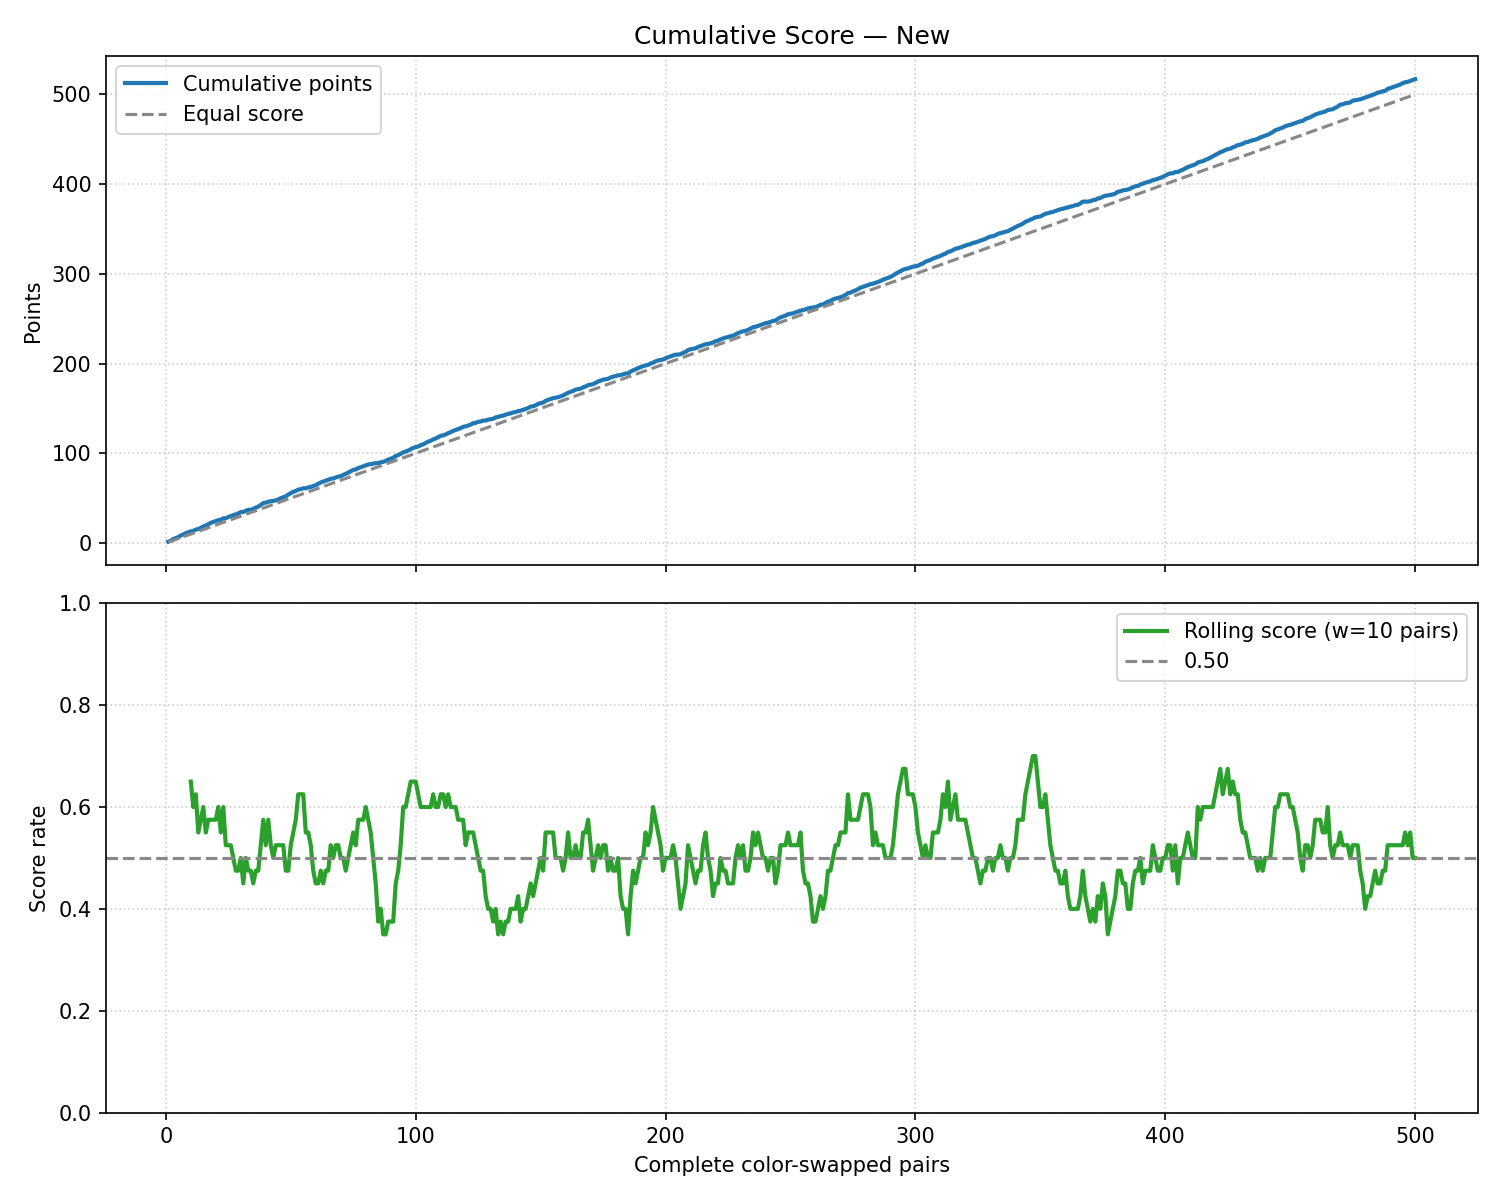


📈 Elo 置信區間收斂圖 (Elo CI)：


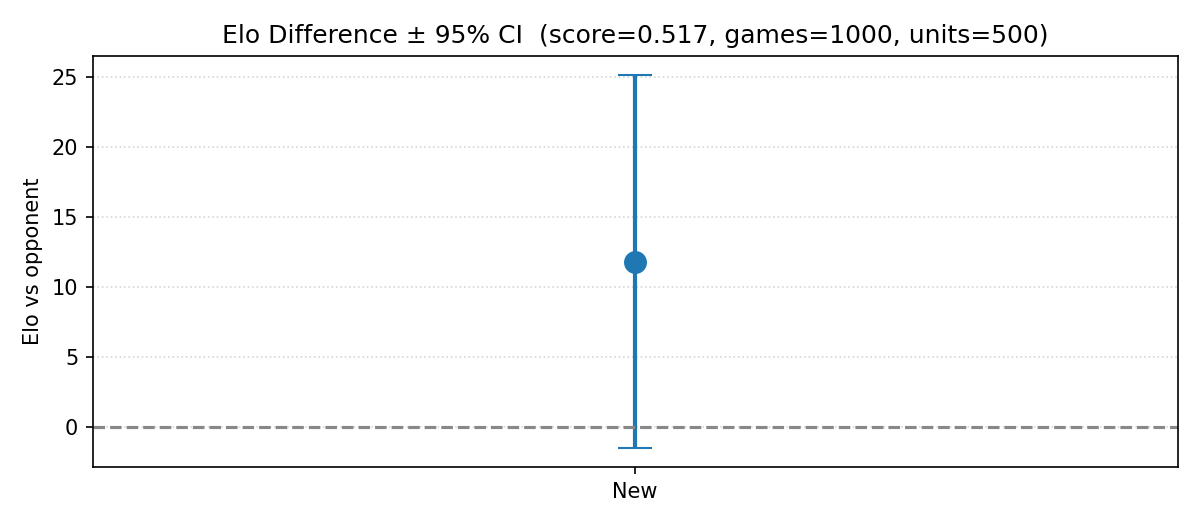


📈 每手搜尋深度 (Depth per Move)：


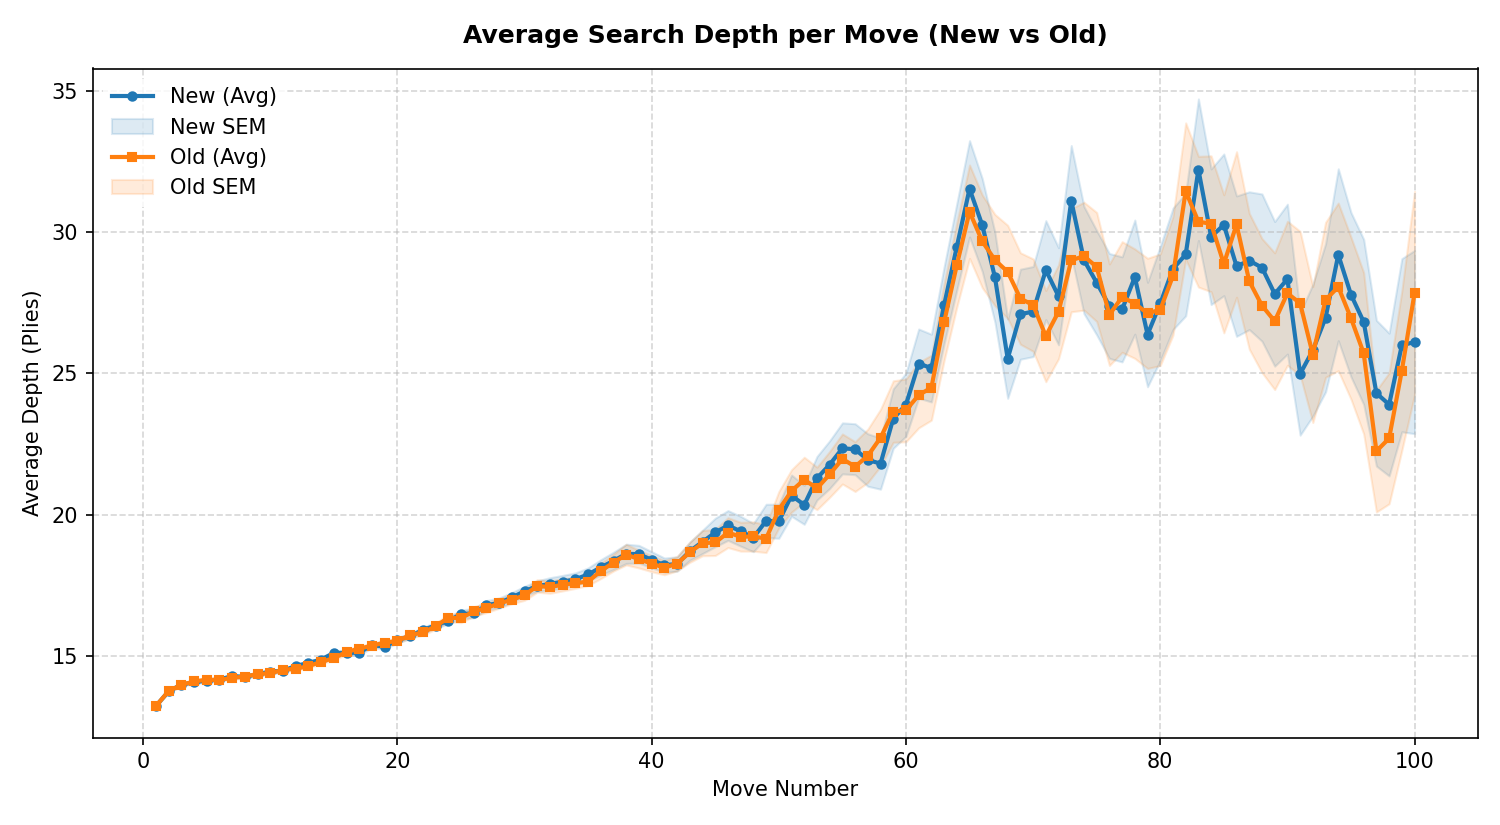


📈 同深度節點比例分佈 (Same-Depth Node Ratio)：


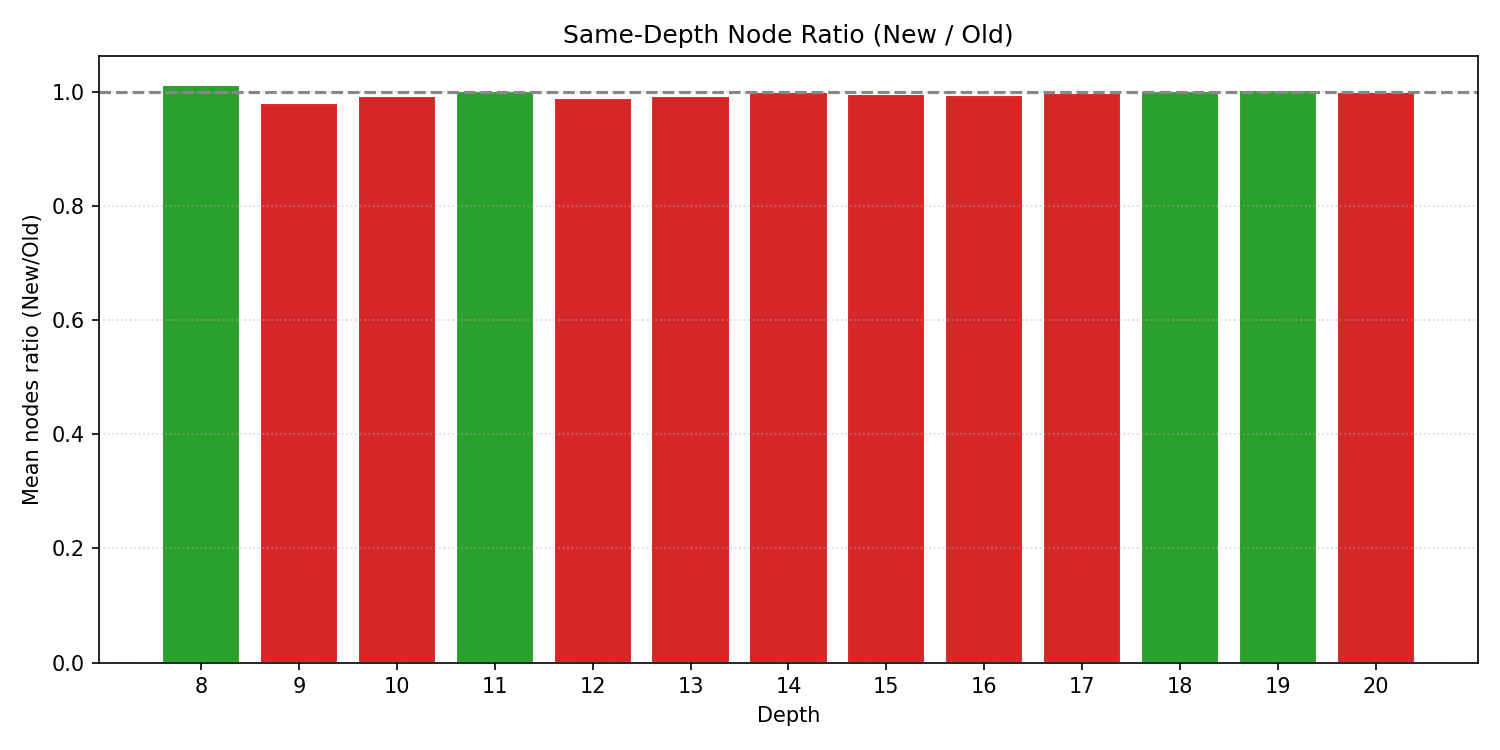


📈 平均節點數 vs 深度散佈 (Avg Nodes vs Depth)：


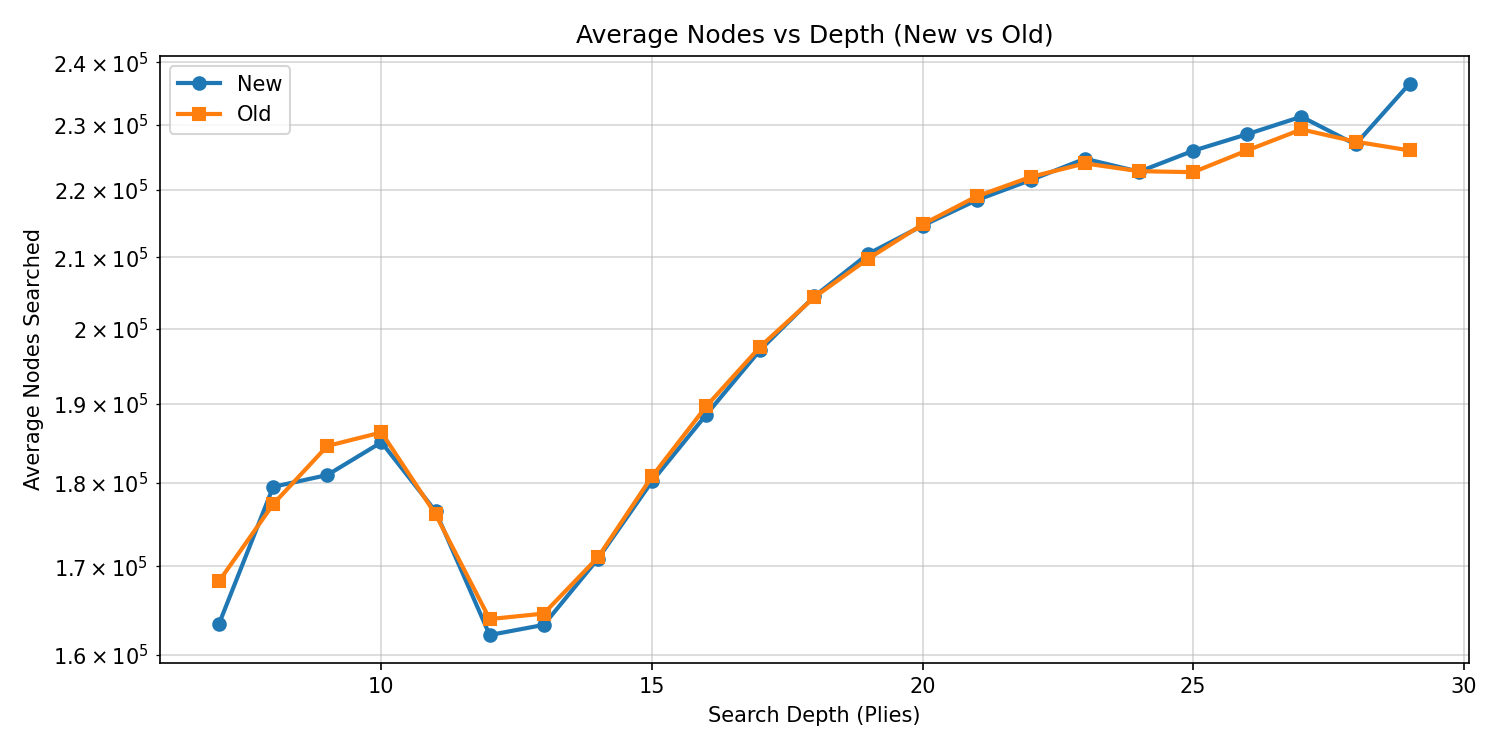


📈 黑白勝負分佈 (WDL by Color)：


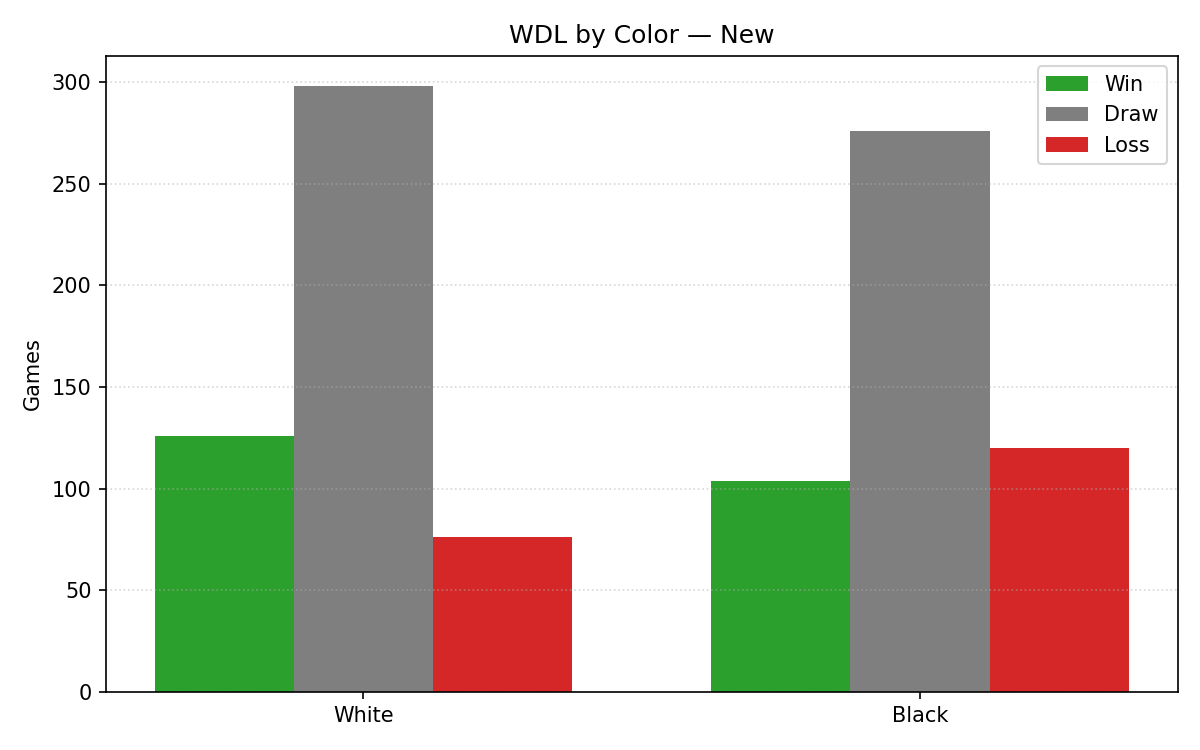

In [2]:
# =====================================================================
# 步驟 6: 視覺化關鍵圖表展示
# =====================================================================
import os
from IPython.display import Image, display

charts = [
    ("累積分數曲線 (Cumulative Score)", "tournament_analysis/cumulative_score.png"),
    ("Elo 置信區間收斂圖 (Elo CI)", "tournament_analysis/elo_ci.png"),
    ("每手搜尋深度 (Depth per Move)", "tournament_analysis/depth_per_move.png"),
    ("同深度節點比例分佈 (Same-Depth Node Ratio)", "tournament_analysis/same_depth_node_ratio.png"),
    ("平均節點數 vs 深度散佈 (Avg Nodes vs Depth)", "tournament_analysis/avg_nodes_vs_depth.png"),
    ("黑白勝負分佈 (WDL by Color)", "tournament_analysis/wdl_by_color.png"),
]

for title, path in charts:
    if os.path.exists(path):
        print(f"\n📈 {title}：")
        display(Image(filename=path))


In [ ]:
# =====================================================================
# 步驟 7: 一鍵打包所有報告、圖表與 PGN 棋譜並下載
# =====================================================================
import datetime

timestamp = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
zip_filename = f"tournament_results_{timestamp}.zip"

!zip -q {zip_filename} tournament_analysis/*.png tournament_analysis/*.txt tournament_analysis/tournament_results.pgn
print(f"📦 已打包完成: {zip_filename}")

try:
    from google.colab import files
    files.download(zip_filename)
    print("⬇️ 已觸發下載！")
except ImportError:
    print(f"💡 本地環境執行，壓縮包位於當前目錄: {zip_filename}")


In [ ]:
from google.colab import runtime

# 執行這行會直接中斷並釋放目前使用的虛擬機器運算資源
runtime.unassign()
